## Setup and Imports

In [1]:
import sys
from pathlib import Path

# Add parent directory to path for imports
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import laspy
import numpy as np
import pandas as pd
from pyntcloud import PyntCloud
import matplotlib.pyplot as plt

print(f"✅ Project root: {PROJECT_ROOT}")
print(f"✅ All imports successful")

✅ Project root: /home/nvidia/projects/fvc_structure/phase_5_3d_cnn_training
✅ All imports successful


## Configuration

In [2]:
# Input directory containing LAS files with structure + treeID
INPUT_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid")

# Preprocessed dirs (produced earlier)

OUT_PLY_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/")


OUT_PLY_DIR.mkdir(parents=True, exist_ok=True)

# Output dir for reconstructed LAS
OUT_LAS_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/")
# OUT_LAS_DIR = Path("/home/nvidia/projects/fvc_structure/phase_5_3d_cnn_training/voxel_data_ready/")
OUT_LAS_DIR.mkdir(parents=True, exist_ok=True)

# Processing parameters
VOXEL_SIZE = 0.10  # 10 cm voxels
IGNORE_INDEX = -100  # PyTorch convention for ignored labels

# Class mapping: LAS classification codes -> model class IDs
CLASS_REMAP = {
    64: 0,  # Forb
    65: 1,  # Woody debris
    66: 2,  # Hummock
    67: 3,  # Shrub
    68: 4,  # Mallee
    0: IGNORE_INDEX,  # Unmatched / background
}

# model class ID -> LAS classification codes
REVERSE_CLASS_MAP = {v: k for k, v in CLASS_REMAP.items() if v != IGNORE_INDEX}
REVERSE_CLASS_MAP[IGNORE_INDEX] = 0  # ignore -> unclassified

LAS_VERSION = "1.4"
POINT_FORMAT = 6
DEFAULT_SCALES = (0.001, 0.001, 0.001)  # 1 mm
# Precision for LAS storage
# LAS_SCALE = (0.001, 0.001, 0.001)  # 1 mm; use (0.01,0.01,0.01) for 1 cm if you want smaller files


print(f"📂 Input LAS:        {INPUT_DIR}")
print(f"📂 PLY folder:       {OUT_PLY_DIR}")
print(f"📂 Output LAS:       {OUT_LAS_DIR}")
print(f"📐 Voxel size:       {VOXEL_SIZE} m")
print(f"🏷️  Classes used:    {len([k for k in CLASS_REMAP if CLASS_REMAP[k] != IGNORE_INDEX])}")


📂 Input LAS:        /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid
📂 PLY folder:       /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply
📂 Output LAS:       /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las
📐 Voxel size:       0.1 m
🏷️  Classes used:    5


In [3]:
# -----------------------------------------------------------------------------
# HELPER FUNCTIONS
# -----------------------------------------------------------------------------

def _guess_original_las_for(stem: str) -> Path:
    """
    Try to map a derived file back to the original LAS tile name.
    Adjust here if your naming differs.
    """
    base = stem
    base = base.replace("_from_ply", "").replace("_from_npz", "")
    base = base.replace("_knnclustering", "")  # if you have those
    return INPUT_DIR / f"{base}.las"



## Convert Back to LAS Format

You can convert NPZ or PLY files back to LAS for visualization in CloudCompare or other LAS viewers.

In [4]:
# good
from pathlib import Path
import numpy as np
import laspy
from pyntcloud import PyntCloud

# -----------------------------------------------------------------------------
# CONVERSION FUNCTIONS
# -----------------------------------------------------------------------------

def npz_to_las(npz_path, out_las_path, original_las_path=None):
    """Convert NPZ file back to LAS format with original CRS and header.
    
    Args:
        npz_path: Path to NPZ file
        out_las_path: Output LAS path
        original_las_path: Optional path to original LAS to preserve CRS and header
    """
    print(f"Converting {npz_path.name} → {out_las_path.name}")
    
    # Load NPZ data
    data = np.load(npz_path)
    feats = data['feats']  # [x_local, y_local, z_local, z_norm, intensity]
    semantic = data['semantic_label']
    instance = data['instance_label']
    offset = data['offset']
    
    # Try to get original LAS for header and CRS
    if original_las_path and Path(original_las_path).exists():
        original_las = laspy.read(original_las_path)
        header_offset = np.array(original_las.header.offsets, dtype=np.float64)
        header_scale = np.array(original_las.header.scales, dtype=np.float64)
        print(f"  Using original header from {Path(original_las_path).name}")
        use_original_header = True
    elif 'header_offset' in data and 'header_scale' in data:
        header_offset = data['header_offset']
        header_scale = data['header_scale']
        print(f"  Using saved header: offset={header_offset}, scale={header_scale}")
        use_original_header = False
    else:
        # Fallback: compute from data
        xyz_local = feats[:, :3]
        xyz_abs = xyz_local + offset
        header_offset = xyz_abs.min(axis=0)
        header_scale = [0.001, 0.001, 0.001]
        print(f"  ⚠️ No original header found, using computed offset")
        use_original_header = False
    
    # Reconstruct absolute coordinates
    xyz_local = feats[:, :3]
    xyz_abs = xyz_local + offset
    z_norm = feats[:, 3]
    intensity = feats[:, 4]
    
    # Reverse class mapping (model class ID → LAS classification code)
    reverse_map = {v: k for k, v in CLASS_REMAP.items() if v != IGNORE_INDEX}
    reverse_map[IGNORE_INDEX] = 0  # Map ignore back to unclassified
    
    las_class = np.array([reverse_map.get(int(c), 0) for c in semantic], dtype=np.uint8)
    
    # Create LAS header with ORIGINAL offset and scale
    header = laspy.LasHeader(version="1.4", point_format=6)
    header.offsets = header_offset
    header.scales = header_scale
    
    # Copy CRS from original if available
    if use_original_header and original_las_path:
        # Copy VLRs (Variable Length Records) which contain CRS info
        for vlr in original_las.header.vlrs:
            header.vlrs.append(vlr)
        print(f"  ✅ Copied {len(original_las.header.vlrs)} VLRs (including CRS)")
    
    # Create LAS data
    las = laspy.LasData(header)
    
    # Set coordinates (will use header offset/scale)
    las.x = xyz_abs[:, 0]
    las.y = xyz_abs[:, 1]
    las.z = xyz_abs[:, 2]
    
    # Set classification
    las.classification = las_class
    
    # Smart intensity conversion: match original range if available
    intensity_min = intensity.min()
    intensity_max = intensity.max()
    print(f"  Intensity range in NPZ: [{intensity_min:.4f}, {intensity_max:.4f}]")
    
    if use_original_header and original_las_path:
        # Match the original LAS intensity range exactly
        orig_int_min = original_las.intensity.min()
        orig_int_max = original_las.intensity.max()
        print(f"  Original LAS intensity: [{orig_int_min}, {orig_int_max}]")
        
        # Scale from NPZ range to original range
        if intensity_max > intensity_min:
            las.intensity = (
                (intensity - intensity_min) / (intensity_max - intensity_min) * 
                (orig_int_max - orig_int_min) + orig_int_min
            ).astype(np.uint16)
        else:
            las.intensity = np.full(len(intensity), orig_int_min, dtype=np.uint16)
        
        print(f"  ✅ Intensity rescaled to match original range")
        print(f"  Reconstructed intensity: [{las.intensity.min()}, {las.intensity.max()}]")
    else:
        # No original available - use heuristics
        if intensity_max <= 1.0:
            # Normalized 0-1 range → scale to 0-65535
            las.intensity = (intensity * 65535).astype(np.uint16)
            print(f"  Intensity scaled from [0,1] to [0,65535]")
        elif intensity_max <= 255:
            # 8-bit range → scale to 16-bit
            las.intensity = (intensity * 256).astype(np.uint16)
            print(f"  Intensity scaled from 8-bit to 16-bit")
        else:
            # Already in higher range → use directly (clamp to uint16)
            las.intensity = np.clip(intensity, 0, 65535).astype(np.uint16)
            print(f"  Intensity used directly (clamped to uint16)")
    
    # Add extra dimensions
    las.add_extra_dim(laspy.ExtraBytesParams(name="Z_norm", type=np.float32))
    las.add_extra_dim(laspy.ExtraBytesParams(name="treeID", type=np.uint16))
    las.add_extra_dim(laspy.ExtraBytesParams(name="class_id", type=np.int32))
    
    las["Z_norm"] = z_norm.astype(np.float32)
    las["treeID"] = instance.astype(np.uint16)
    las["class_id"] = semantic.astype(np.int32)
    
    # Write LAS file
    las.write(str(out_las_path))
    print(f"✅ Saved: {out_las_path}")
    return out_las_path

def ply_to_las(
    ply_path,
    out_las_path,
    original_las_path=None,
    *,
    offset_npy_path=None,
    npz_path=None,
    point_format=6,
):
    """
    Convert PLY back to LAS robustly.

    Key behavior:
    - If PLY coords look LOCAL (small numbers), reconstruct GLOBAL coords by adding:
        1) offset_npy_path if provided and exists
        2) else offset from npz_path if provided
        3) else fallback: pure translation so mins match original (NO scaling)
    - If PLY coords look GLOBAL already, keep them as-is.

    Copies CRS/VLRs from original_las_path when available.
    """
    ply_path = Path(ply_path)
    out_las_path = Path(out_las_path)
    original_las_path = Path(original_las_path) if original_las_path else None
    offset_npy_path = Path(offset_npy_path) if offset_npy_path else None
    npz_path = Path(npz_path) if npz_path else None

    print(f"Converting {ply_path.name} → {out_las_path.name}")

    # --- load PLY ---
    df = PyntCloud.from_file(str(ply_path)).points
    xyz = df[["x", "y", "z"]].to_numpy(dtype=np.float64)

    # --- read original LAS if present (for CRS/header + sanity) ---
    orig = None
    if original_las_path and original_las_path.exists():
        orig = laspy.read(str(original_las_path))
        orig_min = np.array([orig.x.min(), orig.y.min(), orig.z.min()], dtype=np.float64)
        orig_max = np.array([orig.x.max(), orig.y.max(), orig.z.max()], dtype=np.float64)
        print(f"  ✅ Using original header from {original_las_path.name}")
    else:
        orig_min = orig_max = None
        if original_las_path:
            print(f"  ⚠️ Original LAS not found: {original_las_path}")

    ply_min = xyz.min(axis=0)
    ply_max = xyz.max(axis=0)

    # Heuristic: "local" clouds are typically near 0..tile_size,
    # while global CRS coords are large (e.g., 4e5 / 6e6).
    is_ply_local = np.all(np.abs(ply_min) < 1e4) and np.all(np.abs(ply_max) < 1e4)

    xyz_abs = xyz.copy()

    # --- If local, try to restore global coords using offset ---
    if is_ply_local:
        offset = None

        # 1) sidecar offset_npy
        if offset_npy_path and offset_npy_path.exists():
            offset = np.load(str(offset_npy_path)).astype(np.float64)
            print(f"  ✅ Restored global coords using sidecar: {offset_npy_path.name}")

        # 2) offset embedded in NPZ
        elif npz_path and npz_path.exists():
            d = np.load(str(npz_path))
            if "offset" in d:
                offset = d["offset"].astype(np.float64)
                print(f"  ✅ Restored global coords using NPZ offset: {npz_path.name}")

        # 3) fallback: translation only to match original mins (NO scaling!)
        if offset is not None:
            xyz_abs = xyz + offset
        else:
            if orig_min is None:
                raise ValueError(
                    "PLY appears LOCAL but no offset provided and no original LAS available for fallback translation."
                )
            shift = orig_min - ply_min
            xyz_abs = xyz + shift
            print(f"  🔧 No offset found; applied translation to match original mins: {shift}")

    else:
        print("  ✅ PLY already looks GLOBAL; using coordinates as-is")

    # --- build LAS header ---
    header = laspy.LasHeader(version="1.4", point_format=point_format)

    # If we have original, reuse its offsets/scales + CRS VLRs
    if orig is not None:
        header.offsets = np.array(orig.header.offsets, dtype=np.float64)
        header.scales  = np.array(orig.header.scales, dtype=np.float64)

        # copy CRS/VLRs
        for vlr in orig.header.vlrs:
            header.vlrs.append(vlr)
        print(f"  ✅ Copied {len(orig.header.vlrs)} VLRs (including CRS)")
    else:
        # fallback: reasonable defaults
        header.scales = np.array([0.001, 0.001, 0.001], dtype=np.float64)
        header.offsets = xyz_abs.min(axis=0)

    # --- create LAS ---
    las = laspy.LasData(header)
    las.x = xyz_abs[:, 0]
    las.y = xyz_abs[:, 1]
    las.z = xyz_abs[:, 2]

    # --- classification / attributes ---
    if "semantic_seg" in df.columns:
        semantic = df["semantic_seg"].to_numpy(dtype=np.int32)
        reverse_map = {v: k for k, v in CLASS_REMAP.items() if v != IGNORE_INDEX}
        reverse_map[IGNORE_INDEX] = 0
        las.classification = np.array([reverse_map.get(int(c), 0) for c in semantic], dtype=np.uint8)

    if "intensity" in df.columns:
        inten = df["intensity"].to_numpy(dtype=np.float32)
        # if normalized -> scale to uint16
        if inten.max() <= 1.0:
            inten = inten * 65535.0
        las.intensity = np.clip(inten, 0, 65535).astype(np.uint16)

    # extras (optional)
    if "z_norm" in df.columns:
        las.add_extra_dim(laspy.ExtraBytesParams(name="Z_norm", type=np.float32))
        las["Z_norm"] = df["z_norm"].to_numpy(dtype=np.float32)

    if "treeID" in df.columns:
        las.add_extra_dim(laspy.ExtraBytesParams(name="treeID", type=np.uint32))
        las["treeID"] = df["treeID"].to_numpy(dtype=np.uint32)

    if "semantic_seg" in df.columns:
        las.add_extra_dim(laspy.ExtraBytesParams(name="class_id", type=np.int32))
        las["class_id"] = semantic.astype(np.int32)

    # --- write ---
    las.write(str(out_las_path))
    print(f"✅ Saved: {out_las_path}")

    # useful debug
    print(f"  PLY min/max:  {ply_min} / {ply_max}")
    print(f"  LAS min/max:  {xyz_abs.min(axis=0)} / {xyz_abs.max(axis=0)}")
    return out_las_path


In [5]:
# -----------------------------------------------------------------------------
# DISCOVER FILES
# -----------------------------------------------------------------------------

ply_files = sorted(OUT_PLY_DIR.glob("*.ply"))


print(f"\n🔎 Found {len(ply_files)} PLY files")
for f in ply_files[:5]:
    print(f"   PLY: {f.name}")




🔎 Found 15 PLY files
   PLY: znorm_3Dlabels_106.ply
   PLY: znorm_3Dlabels_109.ply
   PLY: znorm_3Dlabels_113.ply
   PLY: znorm_3Dlabels_121.ply
   PLY: znorm_3Dlabels_16.ply


## Convert Files to LAS (with original CRS)

In [37]:
# -----------------------------------------------------------------------------
# RUN ONE SAMPLE (easy sanity check)
# -----------------------------------------------------------------------------

if npz_files:
    sample = npz_files[0]
    orig_las = _guess_original_las_for(sample.stem)
    out_las = OUT_LAS_DIR / f"{sample.stem}_from_npz.las"
    npz_to_las(sample, out_las, original_las_path=orig_las if orig_las.exists() else None)

if ply_files:
    sample = ply_files[0]
    orig_las = _guess_original_las_for(sample.stem)
    out_las = OUT_LAS_DIR / f"{sample.stem}_from_ply.las"
    
    # Look for offset from ForestFormer NPY preprocessing
    # (forestformer3d_npz folder actually contains .npy files, not .npz)
    forestformer_npy_dir = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_npz/")
    offset_npy = forestformer_npy_dir / f"{sample.stem}_offsets.npy"
    
    ply_to_las(
        sample, 
        out_las, 
        original_las_path=orig_las if orig_las.exists() else None,
        offset_npy_path=offset_npy if offset_npy.exists() else None
    )


Converting znorm_3Dlabels_106.npz → znorm_3Dlabels_106_from_npz.las
  Using original header from znorm_3Dlabels_106.las
  ✅ Copied 3 VLRs (including CRS)
  Intensity range in NPZ: [0.0000, 0.4157]
  Original LAS intensity: [0, 106]
  ✅ Intensity rescaled to match original range
  Reconstructed intensity: [0, 106]
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_npz.las
Converting znorm_3Dlabels_106.ply → znorm_3Dlabels_106_from_ply.las
  ✅ Using original header from znorm_3Dlabels_106.las
  ✅ Restored global coords using sidecar: znorm_3Dlabels_106_offsets.npy


  ✅ Copied 3 VLRs (including CRS)
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_ply.las
  PLY min/max:  [0. 0. 0.] / [30.70000076 30.70000076  4.92000008]
  LAS min/max:  [17.5352179  15.81110081  0.        ] / [48.23521866 46.51110158  4.92000008]


In [38]:
from pathlib import Path

# -----------------------------------------------------------------------------
# RUN ONE SAMPLE (easy sanity check)
# -----------------------------------------------------------------------------

OUT_LAS_DIR.mkdir(parents=True, exist_ok=True)

# --- NPZ sample ---
if npz_files:
    sample_npz = Path(npz_files[0])
    orig_las = _guess_original_las_for(sample_npz.stem)
    orig_las_used = orig_las if orig_las.exists() else None

    out_las = OUT_LAS_DIR / f"{sample_npz.stem}_from_npz.las"
    print("\n================ NPZ SAMPLE ================")
    print("NPZ:", sample_npz)
    print("Orig LAS:", orig_las_used if orig_las_used else "❌ not found")
    print("Out LAS:", out_las)

    npz_to_las(sample_npz, out_las, original_las_path=orig_las_used)

# --- PLY sample ---
if ply_files:
    sample_ply = Path(ply_files[0])
    orig_las = _guess_original_las_for(sample_ply.stem)
    orig_las_used = orig_las if orig_las.exists() else None

    out_las = OUT_LAS_DIR / f"{sample_ply.stem}_from_ply.las"

    # If you saved local PLYs, you should also have a sidecar offset:
    offset_sidecar = sample_ply.with_name(sample_ply.stem + "_offset.npy")

    # Optional fallback: matching NPZ (contains offset too)
    npz_fallback = OUT_NPZ_DIR / f"{sample_ply.stem}.npz"

    print("\n================ PLY SAMPLE ================")
    print("PLY:", sample_ply)
    print("Orig LAS:", orig_las_used if orig_las_used else "❌ not found")
    print("Out LAS:", out_las)
    print("Offset sidecar:", offset_sidecar if offset_sidecar.exists() else "❌ not found")
    print("NPZ fallback:", npz_fallback if npz_fallback.exists() else "❌ not found")

    ply_to_las(
        sample_ply,
        out_las,
        original_las_path=orig_las_used,
        offset_npy_path=offset_sidecar if offset_sidecar.exists() else None,
        npz_path=npz_fallback if npz_fallback.exists() else None,
    )



================ NPZ SAMPLE ================
NPZ: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/minsu3d_npz/znorm_3Dlabels_106.npz
Orig LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las
Out LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_npz.las
Converting znorm_3Dlabels_106.npz → znorm_3Dlabels_106_from_npz.las
  Using original header from znorm_3Dlabels_106.las
  ✅ Copied 3 VLRs (including CRS)
  Intensity range in NPZ: [0.0000, 0.4157]
  Original LAS intensity: [0, 106]
  ✅ Intensity rescaled to match original range
  Reconstructed intensity: [0, 106]
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_npz.las

================ PLY SAMPLE ================
PLY: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_106.ply
Orig LAS: /data/c

  ✅ Using original header from znorm_3Dlabels_106.las
  ✅ Restored global coords using sidecar: znorm_3Dlabels_106_offset.npy
  ✅ Copied 3 VLRs (including CRS)
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_ply.las
  PLY min/max:  [0. 0. 0.] / [30.70000076 30.70000076  4.92000008]
  LAS min/max:  [4.6167947e+05 6.2375062e+06 5.7830000e+01] / [4.61710170e+05 6.23753690e+06 6.27500001e+01]


In [39]:
# -----------------------------------------------------------------------------
# RUN ONE SAMPLE (easy sanity check)
# -----------------------------------------------------------------------------

out_dir = OUT_LAS_DIR
out_dir.mkdir(parents=True, exist_ok=True)

# --- NPZ sample ---
if npz_files:
    sample_npz = Path(npz_files[0])

    orig_las = _guess_original_las_for(sample_npz.stem)
    orig_las_used = orig_las if orig_las.exists() else None

    out_las = out_dir / f"{sample_npz.stem}_from_npz.las"

    print("\n================ NPZ SAMPLE ================")
    print(f"NPZ:  {sample_npz}")
    print(f"LAS (orig): {orig_las_used if orig_las_used else '❌ not found'}")
    print(f"LAS (out):  {out_las}")

    npz_to_las(sample_npz, out_las, original_las_path=orig_las_used)

# --- PLY sample ---
if ply_files:
    sample_ply = Path(ply_files[0])

    orig_las = _guess_original_las_for(sample_ply.stem)
    orig_las_used = orig_las if orig_las.exists() else None

    out_las = out_dir / f"{sample_ply.stem}_from_ply.las"

    print("\n================ PLY SAMPLE ================")
    print(f"PLY:  {sample_ply}")
    print(f"LAS (orig): {orig_las_used if orig_las_used else '❌ not found'}")
    print(f"LAS (out):  {out_las}")

    ply_to_las(sample_ply, out_las, original_las_path=orig_las_used)



================ NPZ SAMPLE ================
NPZ:  /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/minsu3d_npz/znorm_3Dlabels_106.npz
LAS (orig): /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las
LAS (out):  /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_npz.las
Converting znorm_3Dlabels_106.npz → znorm_3Dlabels_106_from_npz.las
  Using original header from znorm_3Dlabels_106.las
  ✅ Copied 3 VLRs (including CRS)
  Intensity range in NPZ: [0.0000, 0.4157]
  Original LAS intensity: [0, 106]
  ✅ Intensity rescaled to match original range
  Reconstructed intensity: [0, 106]


✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_npz.las

================ PLY SAMPLE ================
PLY:  /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_106.ply
LAS (orig): /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las
LAS (out):  /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_ply.las
Converting znorm_3Dlabels_106.ply → znorm_3Dlabels_106_from_ply.las
  ✅ Using original header from znorm_3Dlabels_106.las
  🔧 No offset found; applied translation to match original mins: [4.6167947e+05 6.2375062e+06 5.7830000e+01]
  ✅ Copied 3 VLRs (including CRS)
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_ply.las
  PLY min/max:  [0. 0. 0.] / [30.70000076 30.70000076  4.92000008]
  LAS min/max:  [4.61

In [ ]:
# -----------------------------------------------------------------------------
# OPTIONAL: BATCH CONVERT EVERYTHING
# -----------------------------------------------------------------------------

# Uncomment when happy with the sample outputs.
# for f in npz_files:
#     orig_las = _guess_original_las_for(f.stem)
#     out_las = OUT_LAS_DIR / f"{f.stem}_from_npz.las"
#     npz_to_las(f, out_las, original_las_path=orig_las if orig_las.exists() else None)
#
# for f in ply_files:
#     orig_las = _guess_original_las_for(f.stem)
#     out_las = OUT_LAS_DIR / f"{f.stem}_from_ply.las"
#     ply_to_las(f, out_las, original_las_path=orig_las if orig_las.exists() else None)

## Visualize Reconstructed LAS Files

In [40]:
# Load reconstructed LAS file for visualization
reconstructed_dir = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/")
las_files_recon = sorted(reconstructed_dir.glob("*.las"))

if las_files_recon:
    print(f"Found {len(las_files_recon)} reconstructed LAS files:")
    for f in las_files_recon:
        print(f"  {f.name}")
    
    # Load first file
    las_recon = laspy.read(las_files_recon[0])
    print(f"\n📂 Visualizing: {las_files_recon[0].name}")
    print(f"   Total points: {len(las_recon.points):,}")
    print(f"   Extra dimensions: {[d.name for d in las_recon.point_format.extra_dimensions]}")
else:
    print("❌ No reconstructed LAS files found. Run the conversion cells first.")

Found 2 reconstructed LAS files:
  znorm_3Dlabels_106_from_npz.las
  znorm_3Dlabels_106_from_ply.las

📂 Visualizing: znorm_3Dlabels_106_from_npz.las
   Total points: 265,168
   Extra dimensions: ['Z_norm', 'treeID', 'class_id']


In [12]:
# Extract data for plotting
if las_files_recon:
    x = las_recon.x
    y = las_recon.y
    z = las_recon.z
    classification = las_recon.classification
    z_norm = las_recon["Z_norm"]
    tree_ids = las_recon["treeID"]
    class_ids = las_recon["class_id"]
    
    # Subsample for faster plotting
    max_plot_points = 100000
    if len(x) > max_plot_points:
        idx = np.random.choice(len(x), max_plot_points, replace=False)
        x_plot, y_plot, z_plot = x[idx], y[idx], z[idx]
        class_plot = classification[idx]
        znorm_plot = z_norm[idx]
        tree_plot = tree_ids[idx]
        classid_plot = class_ids[idx]
        print(f"Subsampled {len(idx):,} points for visualization")
    else:
        x_plot, y_plot, z_plot = x, y, z
        class_plot = classification
        znorm_plot = z_norm
        tree_plot = tree_ids
        classid_plot = class_ids
        print(f"Plotting all {len(x):,} points")

Subsampled 100,000 points for visualization


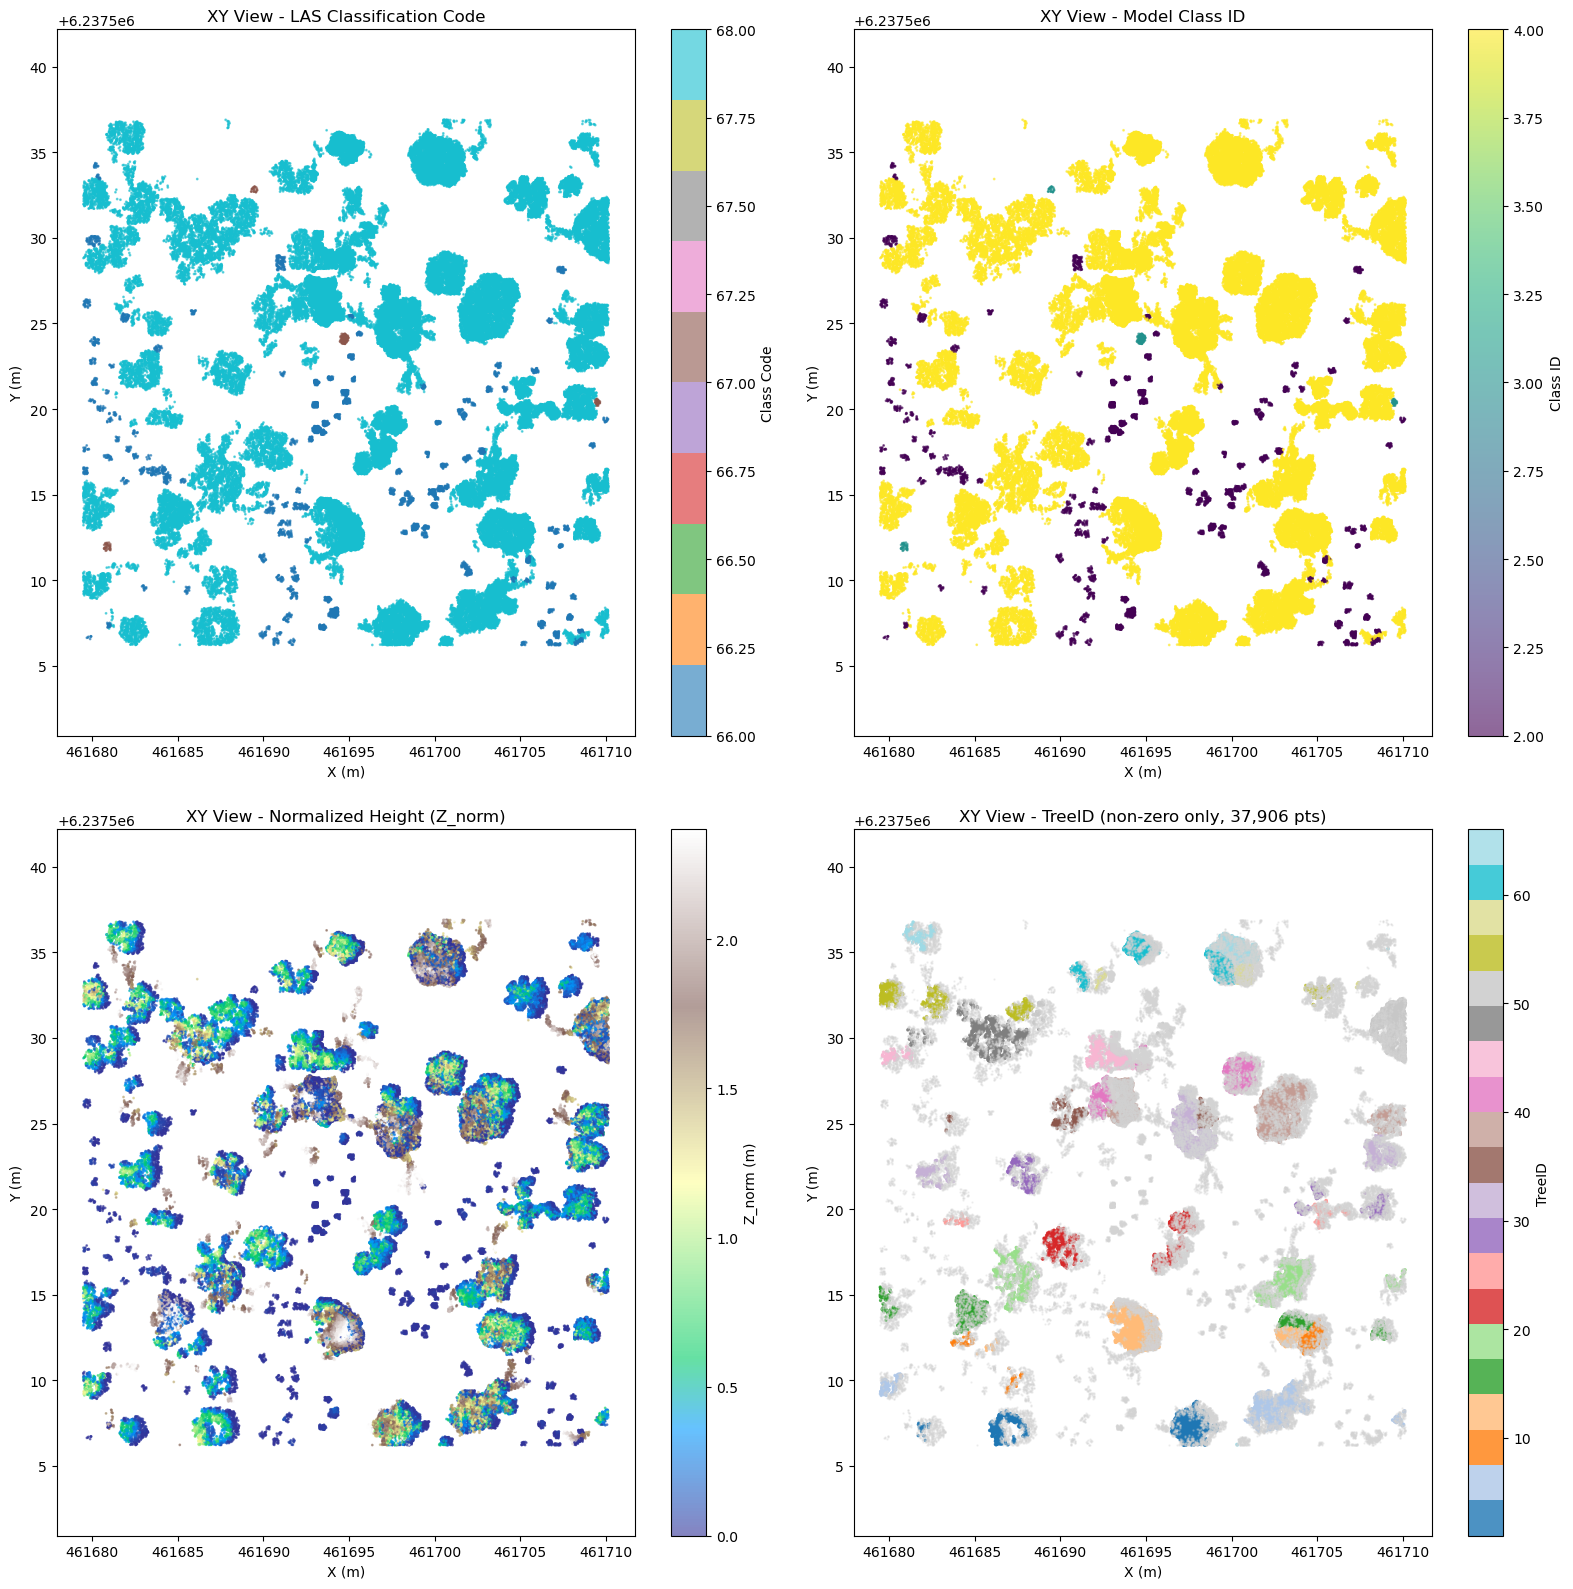

In [13]:
# Plot 1: XY view colored by LAS classification
if las_files_recon:
    fig, axes = plt.subplots(2, 2, figsize=(16, 16))
    
    # Top-left: XY view by LAS classification
    sc1 = axes[0, 0].scatter(x_plot, y_plot, c=class_plot, s=1, cmap='tab10', alpha=0.6)
    axes[0, 0].set_xlabel('X (m)')
    axes[0, 0].set_ylabel('Y (m)')
    axes[0, 0].set_title('XY View - LAS Classification Code')
    axes[0, 0].set_aspect('equal', adjustable='datalim')
    plt.colorbar(sc1, ax=axes[0, 0], label='Class Code')
    
    # Top-right: XY view by model class ID
    sc2 = axes[0, 1].scatter(x_plot, y_plot, c=classid_plot, s=1, cmap='viridis', alpha=0.6)
    axes[0, 1].set_xlabel('X (m)')
    axes[0, 1].set_ylabel('Y (m)')
    axes[0, 1].set_title('XY View - Model Class ID')
    axes[0, 1].set_aspect('equal', adjustable='datalim')
    plt.colorbar(sc2, ax=axes[0, 1], label='Class ID')
    
    # Bottom-left: XY view by Z_norm (height)
    sc3 = axes[1, 0].scatter(x_plot, y_plot, c=znorm_plot, s=1, cmap='terrain', alpha=0.6, vmin=0, vmax=np.percentile(znorm_plot, 95))
    axes[1, 0].set_xlabel('X (m)')
    axes[1, 0].set_ylabel('Y (m)')
    axes[1, 0].set_title('XY View - Normalized Height (Z_norm)')
    axes[1, 0].set_aspect('equal', adjustable='datalim')
    plt.colorbar(sc3, ax=axes[1, 0], label='Z_norm (m)')
    
    # Bottom-right: XY view by treeID
    tree_mask = tree_plot > 0
    if tree_mask.any():
        sc4 = axes[1, 1].scatter(x_plot[tree_mask], y_plot[tree_mask], c=tree_plot[tree_mask], 
                                  s=2, cmap='tab20', alpha=0.8)
        axes[1, 1].scatter(x_plot[~tree_mask], y_plot[~tree_mask], c='lightgray', s=0.5, alpha=0.3)
        axes[1, 1].set_xlabel('X (m)')
        axes[1, 1].set_ylabel('Y (m)')
        axes[1, 1].set_title(f'XY View - TreeID (non-zero only, {tree_mask.sum():,} pts)')
        axes[1, 1].set_aspect('equal', adjustable='datalim')
        plt.colorbar(sc4, ax=axes[1, 1], label='TreeID')
    else:
        axes[1, 1].text(0.5, 0.5, 'No treeID data', ha='center', va='center', transform=axes[1, 1].transAxes)
        axes[1, 1].set_title('XY View - TreeID (none found)')
    
    plt.tight_layout()
    plt.show()

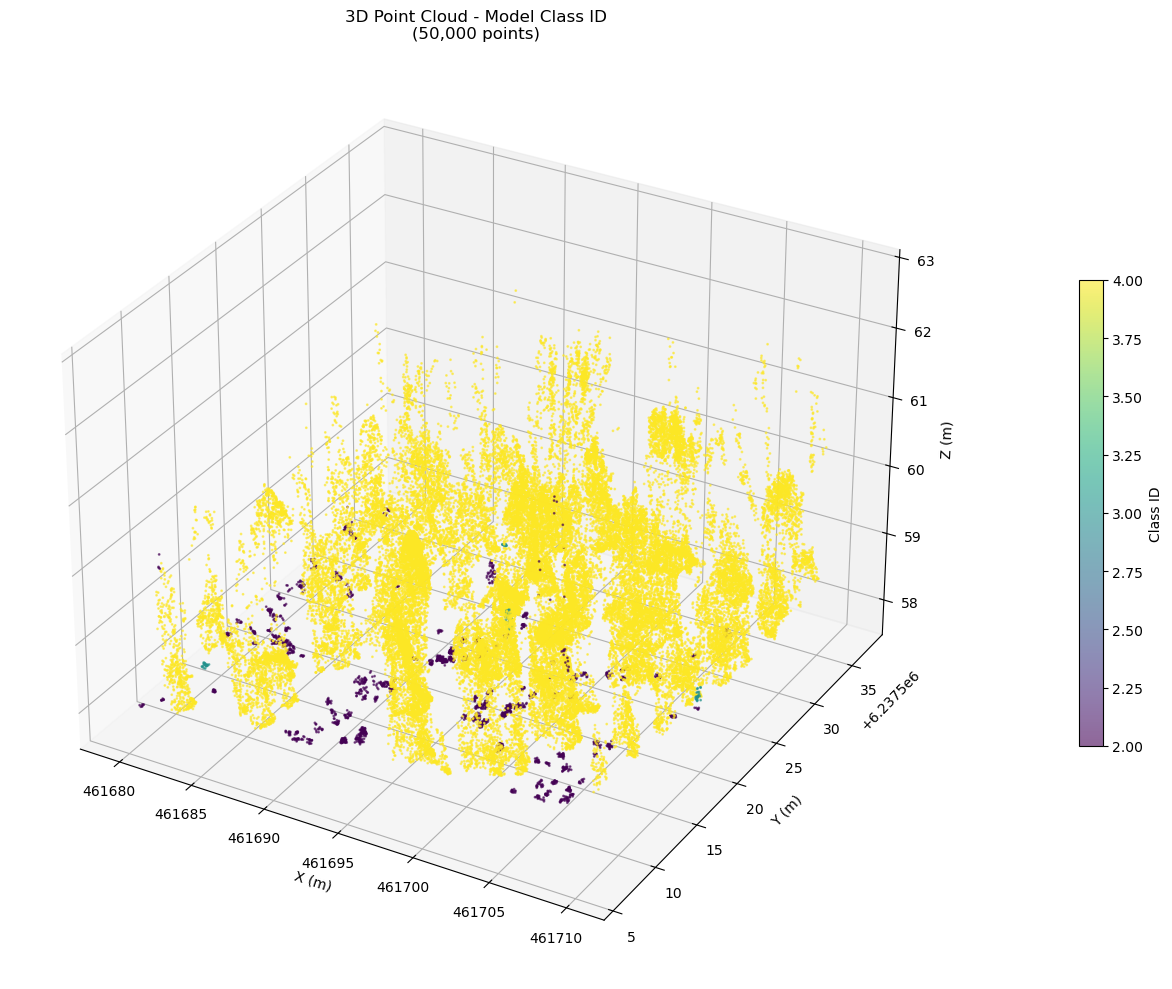


💡 Class mapping:
   LAS 64 → Model ID 0 (Forb)
   LAS 65 → Model ID 1 (Woody debris)
   LAS 66 → Model ID 2 (Hummock)
   LAS 67 → Model ID 3 (Shrub)
   LAS 68 → Model ID 4 (Mallee)


In [17]:
# Plot 2: 3D scatter plot colored by classification
if las_files_recon:
    from mpl_toolkits.mplot3d import Axes3D
    
    fig = plt.figure(figsize=(14, 10))
    
    # 3D view colored by model class ID
    ax = fig.add_subplot(111, projection='3d')
    
    # Further subsample for 3D plot (slower rendering)
    max_3d_points = 50000
    if len(x_plot) > max_3d_points:
        idx_3d = np.random.choice(len(x_plot), max_3d_points, replace=False)
        x_3d = x_plot[idx_3d]
        y_3d = y_plot[idx_3d]
        z_3d = z_plot[idx_3d]
        c_3d = classid_plot[idx_3d]
    else:
        x_3d, y_3d, z_3d = x_plot, y_plot, z_plot
        c_3d = classid_plot
    
    scatter = ax.scatter(x_3d, y_3d, z_3d, c=c_3d, s=1, cmap='viridis', alpha=0.6)
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.set_zlabel('Z (m)')
    ax.set_title(f'3D Point Cloud - Model Class ID\n({len(x_3d):,} points)')
    plt.colorbar(scatter, ax=ax, label='Class ID', shrink=0.5, pad=0.1)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n💡 Class mapping:")
    for las_code, model_id in CLASS_REMAP.items():
        if model_id != IGNORE_INDEX:
            class_names = {0: 'Forb', 1: 'Woody debris', 2: 'Hummock', 3: 'Shrub', 4: 'Mallee'}
            print(f"   LAS {las_code} → Model ID {model_id} ({class_names.get(model_id, 'Unknown')})")


TreeID statistics:
  Unique trees: 65
  Total tree points: 38,097
  Points per tree (mean): 586.1
  Points per tree (median): 251.0
  Points per tree (min/max): 2/4673


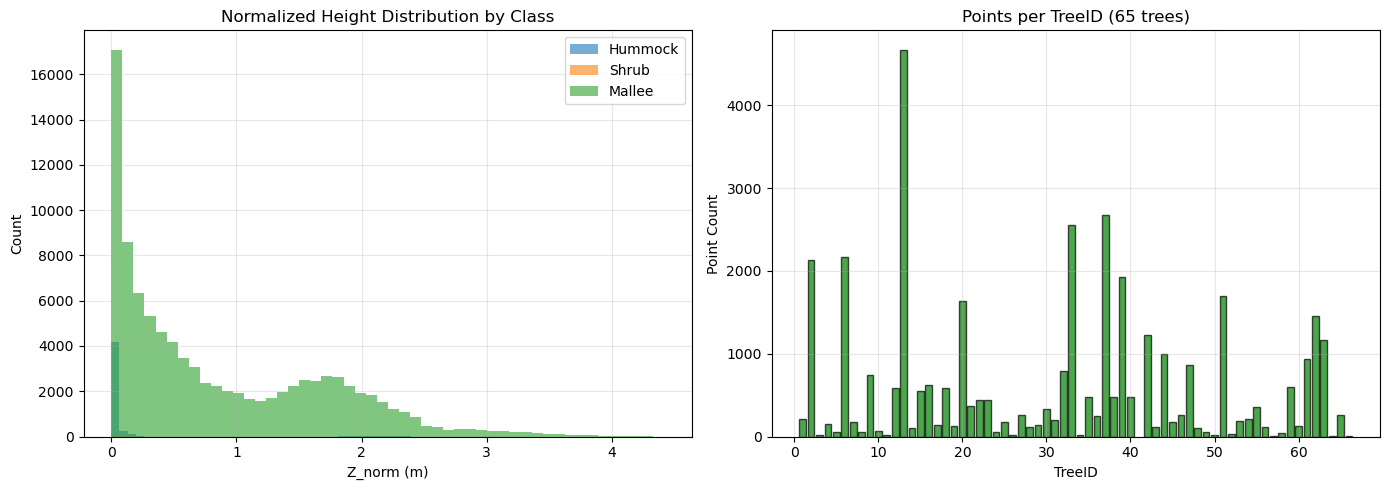

In [18]:
# Plot 3: Height profiles by class
if las_files_recon:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Left: Z_norm histogram by class
    class_names = {0: 'Forb', 1: 'Woody debris', 2: 'Hummock', 3: 'Shrub', 4: 'Mallee', IGNORE_INDEX: 'IGNORE'}
    
    for cls_id in sorted(np.unique(classid_plot)):
        if cls_id == IGNORE_INDEX:
            continue
        mask = classid_plot == cls_id
        if mask.sum() > 0:
            axes[0].hist(znorm_plot[mask], bins=50, alpha=0.6, label=f'{class_names.get(cls_id, cls_id)}')
    
    axes[0].set_xlabel('Z_norm (m)')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Normalized Height Distribution by Class')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Right: TreeID histogram
    tree_nonzero = tree_plot[tree_plot > 0]
    if len(tree_nonzero) > 0:
        unique_trees, counts = np.unique(tree_nonzero, return_counts=True)
        axes[1].bar(unique_trees, counts, color='green', edgecolor='black', alpha=0.7)
        axes[1].set_xlabel('TreeID')
        axes[1].set_ylabel('Point Count')
        axes[1].set_title(f'Points per TreeID ({len(unique_trees)} trees)')
        axes[1].grid(True, alpha=0.3)
        
        print(f"\nTreeID statistics:")
        print(f"  Unique trees: {len(unique_trees)}")
        print(f"  Total tree points: {len(tree_nonzero):,}")
        print(f"  Points per tree (mean): {counts.mean():.1f}")
        print(f"  Points per tree (median): {np.median(counts):.1f}")
        print(f"  Points per tree (min/max): {counts.min()}/{counts.max()}")
    else:
        axes[1].text(0.5, 0.5, 'No treeID data', ha='center', va='center', transform=axes[1].transAxes)
        axes[1].set_title('TreeID Distribution (none found)')
    
    plt.tight_layout()
    plt.show()

In [19]:
# Check if NPZ files have header information
if all_npz:
    sample_npz = Path(all_npz[0])
    data = np.load(sample_npz)
    
    print(f"📂 Checking: {sample_npz.name}")
    print(f"NPZ keys: {list(data.keys())}\n")
    
    if 'header_offset' in data and 'header_scale' in data:
        print("✅ Header information found!")
        print(f"   Original offset: {data['header_offset']}")
        print(f"   Original scale:  {data['header_scale']}")
    else:
        print("⚠️ No header information in NPZ files!")
        print("\nTo preserve original CRS, you need to:")
        print("1. Re-run cell 7 (reload updated process_las function)")
        print("2. Re-run cell 10 (reprocess all LAS files)")
        print("\nThis will create new NPZ files with header_offset and header_scale saved.")

📂 Checking: znorm_3Dlabels_106.npz
NPZ keys: ['coords', 'feats', 'semantic_label', 'instance_label', 'offset']

⚠️ No header information in NPZ files!

To preserve original CRS, you need to:
1. Re-run cell 7 (reload updated process_las function)
2. Re-run cell 10 (reprocess all LAS files)

This will create new NPZ files with header_offset and header_scale saved.
